In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astrotools.constants as c
from astrotools.disk import structure
from astrotools.disk import viscous
from scipy.optimize import curve_fit
import pandas as pd

# HW 3

## Problem 1: Build the Module

### Testing the Functions

#### Test #1: Scale Height

In [2]:
r_AU = c.AU
T = 280

H = structure.scale_height(r_AU, T)
H_AU = H / c.AU
print("The scale height at 1 AU is: %.2g" %H_AU)

The scale height at 1 AU is: 0.033


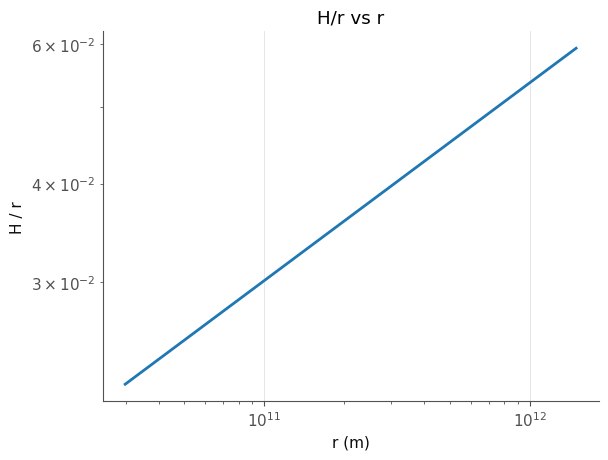

In [230]:
r_arr = c.AU * np.array([0.2, 0.5, 1, 2, 3, 5, 10])
T_arr = 280 * 1/np.sqrt(r_arr / c.AU)
H_arr = structure.scale_height(r_arr, T_arr)

plt.plot(r_arr, H_arr/r_arr)
plt.yscale("log")
plt.xscale("log")
plt.xlabel("r (m)")
plt.ylabel("H / r")
plt.title("H/r vs r")
plt.savefig("test1_hw3_h_vs_r.png")

In [231]:
def f(x, m, b):
    y = m*x + b
    return y

In [232]:
popt, pcov = curve_fit(f, np.log10(r_arr), np.log10(H_arr/r_arr))
m, b = popt
print("The slope of H/r vs r is: %.2g" %m)

The slope of H/r vs r is: 0.25


#### Test #2: SED

In [295]:
r_min = 0.01 * c.AU
r_max = 1e4 * c.AU

test_grid_edges = structure.radial_grid(r_min, r_max)

wl = 100e-6 #meters
nu = c.C_LIGHT / wl
nu_arr = nu * np.array([1/1.01, 1.01]) 

# I used Claude to help me make this lambda function
T_func_1 = lambda r: structure.temperature(r, t_1au = 81.0, slope = -0.75)
f_nu_1 = structure.sed(nu_arr, test_grid_edges, T_func_1, c.PC)

nu_fnu_1 = nu_arr * f_nu_1

T_func_2 = lambda r: structure.temperature(r, t_1au = 160.0, slope = -3/7)
f_nu_2 = structure.sed(nu_arr, test_grid_edges, T_func_2, c.PC)

nu_fnu_2 = nu_arr * f_nu_2

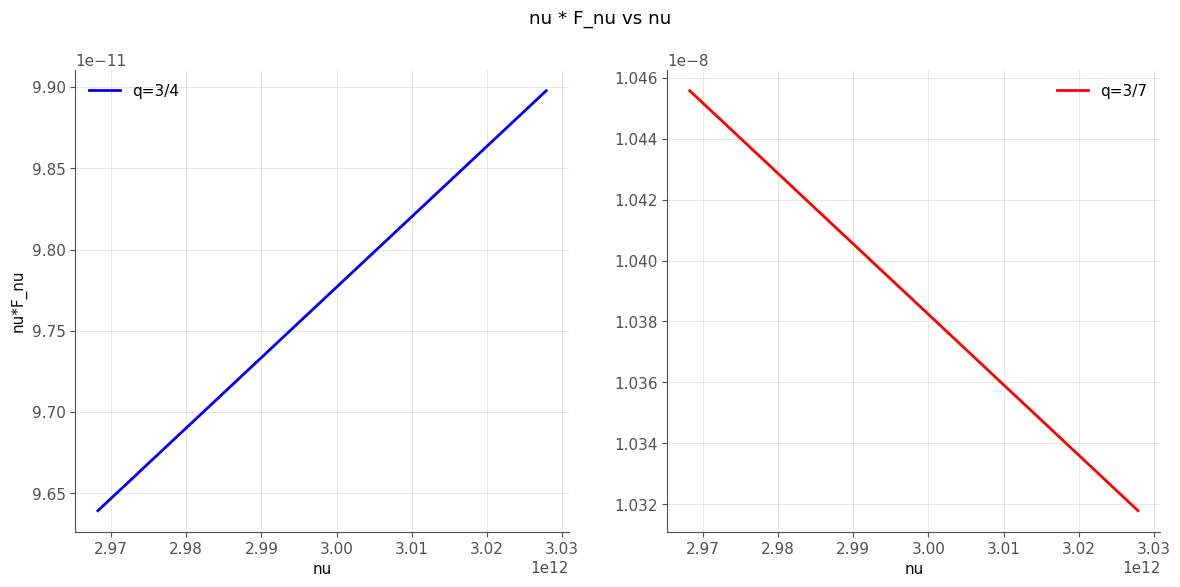

In [299]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize = [14, 6])
ax1.plot(nu_arr, nu_fnu_1, color = 'blue', label = 'q=3/4')
ax2.plot(nu_arr, nu_fnu_2, color = 'red', label = 'q=3/7')
ax1.set_ylabel("nu*F_nu")
ax1.set_xlabel("nu")
ax2.set_xlabel("nu")
ax1.legend()
ax2.legend()
plt.suptitle("nu * F_nu vs nu")
plt.savefig("test2_q.png")

In [239]:
popt, pcov = curve_fit(f, np.log10(nu_arr), np.log10(nu_fnu_1))
m_1, b = popt
print("The slope of nu*f_nu around 100 microns is: %.3g for q=3/4" %m_1)

The slope of nu*f_nu around 100 microns is: 1.33 for q=3/4


/home/miricaradonna/.local/lib/python3.8/site-packages/scipy/optimize/_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


In [240]:
popt, pcov = curve_fit(f, np.log10(nu_arr), np.log10(nu_fnu_2))
m_2, b = popt
print("The slope of nu*f_nu around 100 microns is: %.3g for q=3/7" %m_2)

The slope of nu*f_nu around 100 microns is: -0.667 for q=3/7


#### Test #3: SED part 2

In [241]:
T = 20
wl = 1.3e-3 #m
nu = c.C_LIGHT / wl

T_func_3 = lambda r: structure.temperature(r, t_1au = 20, slope = 0)
f_nu_3 = structure.sed(nu, test_grid_edges, T_func_3, c.PC, sigma_dust=structure.surface_density, kappa=structure.dust_opacity)

kappa_nu = structure.dust_opacity(nu)
B_nu = structure.planck_nu(nu, T)

r_mid = np.sqrt(test_grid_edges[:-1] * test_grid_edges[1:])
area_arr = np.pi * np.diff(test_grid_edges**2)
M_dust = np.sum(structure.surface_density(r_mid) * area_arr)

In [242]:
print("The sed function returned an f_nu at 1.3 mm of: %.3g" %f_nu_3)

analytic_fnu = kappa_nu * B_nu * M_dust / (c.PC)**2
print("The analytic solution for f_nu at 1.3 mm is: %.3g" %analytic_fnu)

The sed function returned an f_nu at 1.3 mm of: 2.38e-20
The analytic solution for f_nu at 1.3 mm is: 2.82e-20


#### Test #4: viscous step

$\tau = 12\nu t / r_{0}^{2}$ $-->$ $t = \tau  r_{0}^{2} / 12\nu$

In [243]:
r_0 = 10 * c.AU
nu_constant = 1e11

rin = 1 * c.AU
rout = 1000 * c.AU 

n_decades = np.log10(rout / rin)
n = int(round(40 * n_decades))

tau_min = 0.01
tau_max = 0.1

M_ring = c.M_SUN 

t_min = tau_min * r_0**2 / (12 * nu_constant)
t_max = tau_max * r_0**2 / (12 * nu_constant)

grid = viscous.make_grid(rin, rout, n)
nu_constant_arr = np.full(grid.n, nu_constant)
dt = viscous.cfl_timestep(grid, nu_constant)
sigma0_arr = viscous.ring_solution(grid.r, t_min, M_ring, r_0, nu_constant)

In [245]:
t, sigma, mass = viscous.evolve(sigma0_arr, grid, nu_constant_arr, t_max, dt)
sigma_analytic = viscous.ring_solution(grid.r, t[-1], mass[0], r_0, nu_constant_arr)

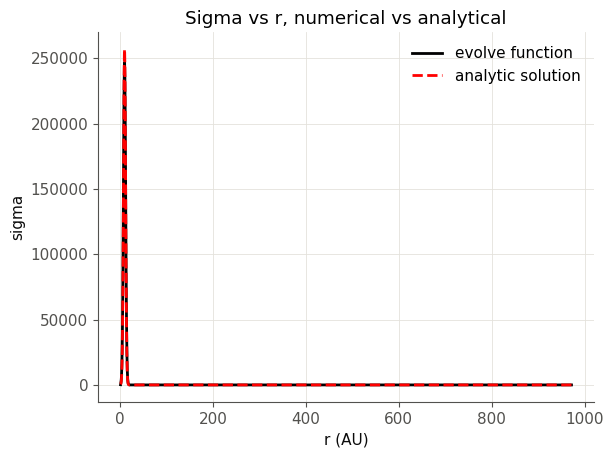

In [250]:
plt.plot(grid.r/c.AU, sigma[-1], label = "evolve function", color = 'black')
plt.plot(grid.r/c.AU, sigma_analytic, label = "analytic solution", color = 'red', linestyle = '--')
plt.xlabel("r (AU)")
plt.ylabel("sigma")
plt.title("Sigma vs r, numerical vs analytical")
plt.legend()
plt.savefig("test4_hw3.png")

## Problem #2: What the Spectrum Means

In [251]:
T_star = 4000
R_star = 2 * c.R_SUN
M_star = c.M_SUN
d = 150 * c.PC

wl_min = 1e-6
wl_max = 3e-3

wl_arr = np.linspace(wl_min, wl_max, 5000)
nu_arr = c.C_LIGHT / wl_arr

F_photosphere = (np.pi * (R_star**2) * structure.planck_nu(nu_arr, T_star)) / d**2
nu_fnu_photosphere = nu_arr * F_photosphere

### Part (a)

In [252]:
r_min = 0.1 * c.AU
r_max = 100 * c.AU
grid_edges = structure.radial_grid(r_min, r_max)


T_flat = lambda r: structure.temperature(r, t_1au = 81.0, slope = -0.75)
T_flared = lambda r: structure.temperature(r, t_1au = 160.0, slope = -3/7)

f_nu_flat = structure.sed(nu_arr, grid_edges, T_flat, d)
f_nu_flared = structure.sed(nu_arr, grid_edges, T_flared, d)

n_fnu_flat = nu_arr * f_nu_flat
n_fnu_flared = nu_arr * f_nu_flared

flat_photo_sum = n_fnu_flat+nu_fnu_photosphere
flared_photo_sum = n_fnu_flared+nu_fnu_photosphere

wl_arr_microns = wl_arr * 1e6

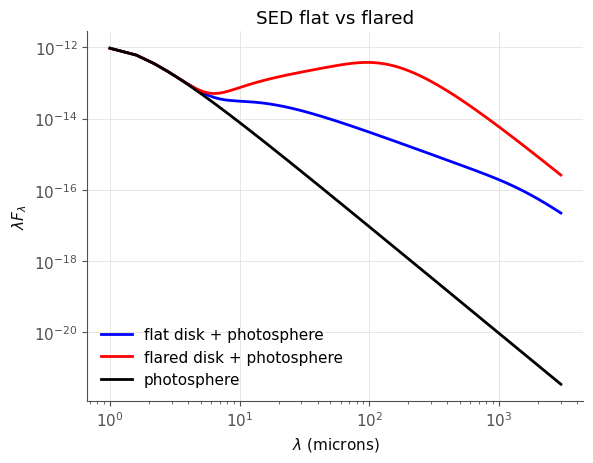

In [253]:
plt.plot(wl_arr_microns, flat_photo_sum , color = 'blue', label = 'flat disk + photosphere')
plt.plot(wl_arr_microns, flared_photo_sum, color = 'red', label = 'flared disk + photosphere')
plt.plot(wl_arr_microns, nu_fnu_photosphere, color = 'black', label = 'photosphere')
plt.yscale("log")
plt.xscale("log")
plt.ylabel(r"$\lambda F_{\lambda}$")
plt.xlabel("$\lambda$ (microns)")
plt.title("SED flat vs flared")
plt.legend()
plt.savefig("prob2a_hw3.png")

In [254]:
index_min = np.searchsorted(wl_arr_microns, 2.2) - 1
index_max = np.searchsorted(wl_arr_microns, 24) - 1

In [255]:
wl_slope_calc = wl_arr_microns[index_min:index_max]
flat_slope_calc = flat_photo_sum[index_min:index_max]
flared_slope_calc = flared_photo_sum[index_min:index_max]

In [256]:
popt_flat, pcov = curve_fit(f, np.log10(wl_slope_calc), np.log10(flat_slope_calc))
m_flat, b_flat = popt_flat

popt_flared, pcov = curve_fit(f, np.log10(wl_slope_calc), np.log10(flared_slope_calc))
m_flared, b_flared = popt_flared

In [257]:
q_arr = np.array([3/4, 3/7])
power_law = -(4 - 2/q_arr)
print("The analytic slope for a flat disk is: %.3g" %power_law[0])
print("The analytic slope for a flared disk is: %.3g" %power_law[1])

print("The slope between 2.2 and 24 microns for the flat disk+photosphere is: %.3g" %m_flat)
print("The slope between 2.2 and 24 microns for the flared disk+photosphere is: %.3g" %m_flared)

The analytic slope for a flat disk is: -1.33
The analytic slope for a flared disk is: 0.667
The slope between 2.2 and 24 microns for the flat disk+photosphere is: -0.923
The slope between 2.2 and 24 microns for the flared disk+photosphere is: 0.152


#### It seems the difference between the slopes I calculated and the analytic solutions is the analytic solutions don't include the flux from the photosphere, which changes the slope at smaller wavelengths

### Part (b)

In [258]:
sigma_0 = 1.7e4
rmin_partb = 0.1 * c.AU
rmax_partb = 30 * c.AU
grid_partb = structure.radial_grid(rmin_partb, rmax_partb)

dust_gas = 0.01
nu = c.C_LIGHT / 1.3e-3

In [259]:
flux_dust = structure.sed(nu, grid_partb, structure.temperature, d, sigma_dust=structure.surface_density, kappa=structure.dust_opacity)
print("The flux at 1.3 mm is: %.3g W m^-2 Hz^-1" %flux_dust)

The flux at 1.3 mm is: 3.03e-27 W m^-2 Hz^-1


In [260]:
M_dust = flux_dust * d**2 / (kappa_nu*B_nu) #kappa_nu and B_nu are from test #3
print("The inferred dust mass is: %.3g kg" %M_dust)

The inferred dust mass is: 1.15e+27 kg


In [261]:
#new function I_v = t_v B_v
def sed_thin(nu, r_edges, T_func, distance, sigma_dust=None, kappa=None, cos_i=1.0):
    r_mid = np.sqrt(r_edges[:-1] * r_edges[1:])
    area = np.pi*(r_edges[1:]**2 - r_edges[:-1]**2)
    T = T_func(r_mid)
    B_nu = structure.planck_nu(nu, T) # T_func

    if sigma_dust == None:
        I_nu = B_nu

    else:
        tau_nu = kappa(nu) * sigma_dust(r_mid)[None,:] / cos_i
        I_nu = tau_nu*B_nu 

    F_nu = (cos_i / distance**2) * np.sum(area*I_nu, axis=1)
    return F_nu

flux_dust_thin = sed_thin(nu, grid_partb, structure.temperature, d, sigma_dust=structure.surface_density, kappa=structure.dust_opacity)
print("The optically thin flux at 1.3 mm is: %.3g W m^-2 Hz^-1" %flux_dust_thin)

M_dust_thin = flux_dust_thin * d**2 / (kappa_nu*B_nu)
print("The inferred dust mass for an optically thin gas is: %.3g kg" %M_dust_thin)

print("The factor is: %.3g" %(M_dust_thin/M_dust))

The optically thin flux at 1.3 mm is: 6.46e-25 W m^-2 Hz^-1
The inferred dust mass for an optically thin gas is: 2.46e+29 kg
The factor is: 213


## Problem #3: How a ring spreads

### Part (a)

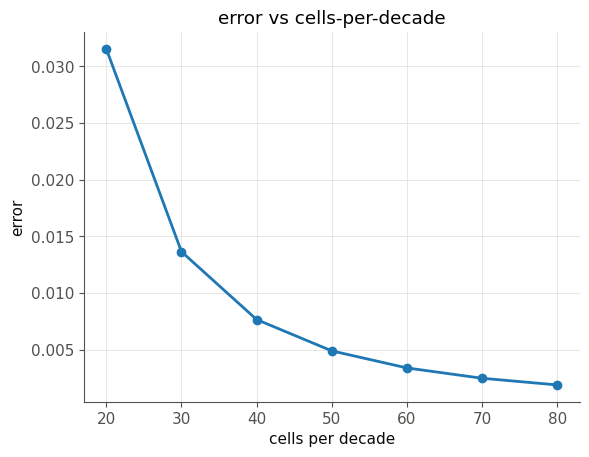

In [264]:
r_0 = 10 * c.AU
nu_constant = 1e11
rin = 1 * c.AU
rout = 1000 * c.AU
M_ring = c.M_SUN 


t_min = 0.01 * r_0**2 / (12 * nu_constant)
t_max = 0.1  * r_0**2 / (12 * nu_constant)

n_decades = np.log10(rout / rin)
n_arr = np.array([20, 30, 40, 50, 60, 70, 80])
err_arr = []

for n in n_arr:
    res = int(round(n * n_decades))
    grid = viscous.make_grid(rin, rout, res)
    nu_constant_arr = np.full(grid.n, nu_constant)
    dt = viscous.cfl_timestep(grid, nu_constant)

    sigma0_arr = viscous.ring_solution(grid.r, t_min, M_ring, r_0, nu_constant)

    t, sigma, mass = viscous.evolve(sigma0_arr, grid, nu_constant_arr, t_max - t_min, dt)
    sigma_analytic = viscous.ring_solution(grid.r, t_max, M_ring, r_0, nu_constant)

    err_arr.append(np.max(np.abs(sigma[-1] - sigma_analytic)) / np.max(sigma_analytic))

plt.plot(n_arr, err_arr, 'o-')
plt.xlabel('cells per decade')
plt.ylabel("error")
plt.title("error vs cells-per-decade")
plt.savefig("prob3a_hw3.png")

#### The order of convergence seems to be first order, since the error halves for each timestep. You need a resolution of at least 40 cells per decade to get an error less than 1%.

### Part (b)

In [265]:
res = int(round(40 * n_decades))
grid = viscous.make_grid(rin, rout, res)
nu_constant_arr = np.full(grid.n, nu_constant)
dt = 1.5 * viscous.cfl_timestep(grid, nu_constant, safety = 1)

sigma0_arr = viscous.ring_solution(grid.r, t_min, M_ring, r_0, nu_constant)

t, sigma, mass = viscous.evolve(sigma0_arr, grid, nu_constant_arr, t_max - t_min, dt)
sigma_analytic = viscous.ring_solution(grid.r, t_max, M_ring, r_0, nu_constant)


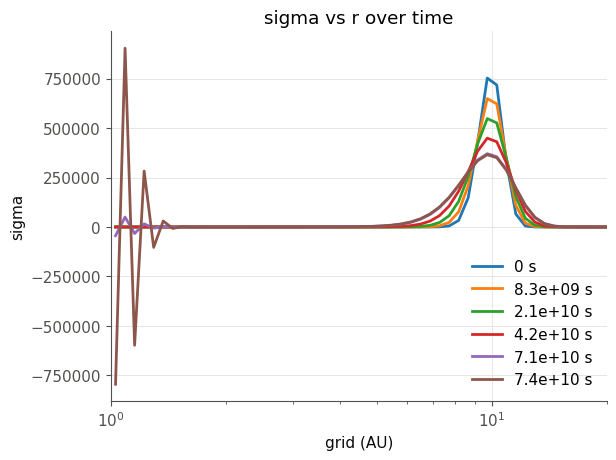

In [266]:
for i in [0, 10, 25, 50, 85, 88]:
    plt.plot(grid.r / c.AU, sigma[i], label = "%.2g s" %t[i])
plt.xscale('log')
plt.xlim(1, 20)
plt.xlabel('grid (AU)')
plt.ylabel("sigma")
plt.legend()
plt.title("sigma vs r over time")
plt.savefig("prob3b_hw3.png")

#### It seems that after t ~ 1e10 s sigma blows up close to the inner edge. 
#### Looking at the function for cfl_timestep, we know that $dt < (\Delta r)^{2} / (6 nu)$ is where the model is stable. Since we increased the safety and increased the timestep, that condition doesn't hold, and the model becomes unstable. Since $\Delta r^{2}$ is smaller at the inner edge, the model blows up at the inner edge before the outer edge.

### Part (c)

In [267]:
res = int(round(40 * n_decades))
grid = viscous.make_grid(rin, rout, res)
nu_constant_arr = np.full(grid.n, nu_constant)
dt = viscous.cfl_timestep(grid, nu_constant)

sigma0_arr = viscous.ring_solution(grid.r, t_min, M_ring, r_0, nu_constant)

t, sigma, mass = viscous.evolve(sigma0_arr, grid, nu_constant_arr, (0.5  * r_0**2 / (12 * nu_constant)) - t_min, dt)
sigma_analytic = viscous.ring_solution(grid.r, (0.5  * r_0**2 / (12 * nu_constant)), M_ring, r_0, nu_constant)

# I used Claude to help me with the code below to find when/where the error is first above 1%

t_abs = t + t_min                                
tau = 12 * nu_constant * t_abs / r_0**2

err = []
for i in range(len(t)):
    sig_an = viscous.ring_solution(grid.r, t_abs[i], M_ring, r_0, nu_constant)
    err.append(np.max(np.abs(sigma[i] - sig_an)) / np.max(sig_an))
err = np.array(err)

i = np.where((tau > 0.1) & (err > 0.01))[0][0]
sig_an = viscous.ring_solution(grid.r, t_abs[i], M_ring, r_0, nu_constant)
diff = np.abs(sigma[i] - sig_an)
k = np.argmax(diff)

print(f"error first exceeds 1% at t = {t_abs[i] / c.MYR:.3f} Myr (tau = {tau[i]:.3f})")
print(f"largest error occurs at r = {grid.r[k] / c.AU:.2f} AU")

error first exceeds 1% at t = 0.008 Myr (tau = 0.133)
largest error occurs at r = 1.03 AU


In [268]:
rin_b = 0.3 * c.AU
n_b = int(round(40 * np.log10(rout / rin_b)))       # still 40 cells per decade
grid_b = viscous.make_grid(rin_b, rout, n_b)
nu_b = np.full(grid_b.n, nu_constant)
dt_b = viscous.cfl_timestep(grid_b, nu_constant)

sig0_b = viscous.ring_solution(grid_b.r, t_min, M_ring, r_0, nu_constant)
t_b, sigma_b, mass_b = viscous.evolve(sig0_b, grid_b, nu_b, t_max - t_min, dt_b, n_out=400)

t_abs_b = t_b + t_min
tau_b = 12 * nu_constant * t_abs_b / r_0**2

err_b = []
for i in range(len(t_b)):
    sig_an = viscous.ring_solution(grid_b.r, t_abs_b[i], M_ring, r_0, nu_constant)
    err_b.append(np.max(np.abs(sigma_b[i] - sig_an)) / np.max(sig_an))
err_b = np.array(err_b)

error_big = np.where((tau_b > 0.1) & (err_b > 0.01))[0] # I used claude to optimize this line of code that finds the error above 1%
if error_big.size > 0:
    sig_an = viscous.ring_solution(grid_b.r, t_abs_b[error_big], M_ring, r_0, nu_constant)
    k = np.argmax(np.abs(sigma_b[i] - sig_an))
    print(f"r_in = 0.3 AU: error exceeds 1% at tau = {tau_b[i]:.3f}, at r = {grid_b.r[k]/c.AU:.2f} AU")
else:
    print(f"r_in = 0.3 AU: error stays below 1%. The maximum error is {err_b.max():.4f}")

r_in = 0.3 AU: error stays below 1%. The maximum error is 0.0191


#### It seems like ring_solution assumes the inner boundary is below 1 AU, since the error stays below 1%, whereas when rin = 1 AU, the error occurs just above rin at 1.03 AU.

## Problem 4: Do the Lupus Disks Drain Viscously?

In [269]:
lupus_disks_full = pd.read_csv("data/ps3/lupus_disks.csv")
lupus_disks = lupus_disks_full.loc[lupus_disks_full['flag'].isna()]
lupus_disks_flag = lupus_disks_full.loc[lupus_disks_full['flag'].notna()]
lupus_disks_full

,name,name_alcala,distance_pc,F890_mJy,e_F890_mJy,F890_limit,M_star_msun,log_mdot,flag
0,Sz 65,Sz65,150,64.49,0.32,0,0.70,-9.57,chromospheric;mdot_upper_limit
1,Sz 66,Sz66,150,14.78,0.29,0,0.29,-8.54,NaN
2,J15445789-3423392,AKC2006-19,150,0.54,NaN,1,0.14,-11.00,NaN
3,J15450887-3417333,SSTc2dJ154508.9-341734,150,46.27,0.50,0,0.14,-8.41,NaN
4,Sz 68,Sz68,150,150.37,0.46,0,1.40,-8.24,chromospheric;mdot_upper_limit
...,...,...,...,...,...,...,...,...,...
61,Sz 123B,Sz123B,200,0.57,NaN,1,0.46,-9.99,subluminous
62,Sz 123A,Sz123A,200,40.64,0.56,0,0.51,-8.86,transitional
63,J16115979-3823383,SST-Lup3-1,200,0.54,NaN,1,0.17,-10.29,NaN
64,J16124373-3815031,SSTc2dJ161243.8-381503,200,29.88,0.49,0,0.44,-8.76,NaN


### Part (a)

In [274]:
def mJy_to_SI(F):
    """
        Takes in F in mJy and returns flux in W/m^2/Hz
        1 Jy = 1e-26 W/m^2/Hz
        1 mJy = 1e-3 Jy
        
    """
    return F * 1e-3 * 1e-26

def calc_M_dust(nu, F, d, T):
    F_SI = mJy_to_SI(F)
    kappa_nu = 0.337 #given in problem
    B_nu = structure.planck_nu(nu, T)

    M_dust = F_SI * d**2 / (kappa_nu * B_nu)

    return M_dust

In [282]:
F_arr = np.array(lupus_disks_full["F890_mJy"])
F_arr_err_clean = np.array(lupus_disks["e_F890_mJy"])

nu_prob4 = c.C_LIGHT / (890 * 1e-6)
dist = c.PC * np.array(lupus_disks_full["distance_pc"])
T = 20

M_dust_arr = calc_M_dust(nu_prob4, F_arr, dist, T)
M_disk_arr = 100 * M_dust_arr / c.M_SUN


In [283]:
log_Mdot = np.array(lupus_disks_full["log_mdot"])

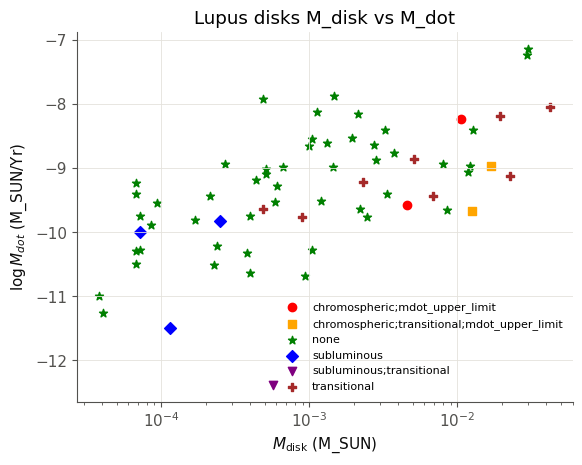

In [285]:
lupus_disks_full['M_disk'] = M_disk_arr     
lupus_disks_full['flag'] = lupus_disks_full['flag'].fillna('none') 

# I used claude to help me get the right code (below) for plotting different flags as different colors/symbols

markers = ['o', 's', '*', 'D', 'v', 'P']
colors = ['red', 'orange','green', 'blue', 'purple', 'brown']

for (flag, group), m, color in zip(lupus_disks_full.groupby('flag'), markers, colors):
    plt.scatter(group['M_disk'], group['log_mdot'], marker=m, label=flag, color=color)

plt.xscale('log')
plt.xlabel(r'$M_{\rm disk}$ (M_SUN)')
plt.ylabel(r'$\log M_{dot}$ (M_SUN/Yr)')
plt.legend(fontsize=8)
plt.title("Lupus disks M_disk vs M_dot")
plt.savefig("prob4a_hw3.png")

### Part (b)

### $M(t) = M_{0}\tilde{t}^{-1/[2(2-\gamma))]}$ 
### $\dot M(t) = \frac{3(2-\gamma)\nu_{1}M_{0}}{2r_{1}^{2}} \tilde{t}^{-(5/2 - \gamma)/(2-\gamma))]}$

### For simplicity, say $-1/[2(2-\gamma))] = a$ and $-(5/2 - \gamma)/(2-\gamma))] = b$

### $\frac{M}{\dot M} = \frac{M_{0} \tilde{t}^{a}}{\frac{3(2-\gamma)\nu_{1}M_{0}}{2r_{1}^{2}}}$
### $M_{0}$ cancels and we get:
### $\frac{M}{\dot M} = \frac{2r_{1}^{2}\tilde{t}^{a-b}}{{3(2-\gamma)\nu_{1}}}$
### However:
### $a - b = -1/[2(2-\gamma)] + (5/2 - \gamma)/(2-\gamma)) =  \frac{4/2 - \gamma}{2 - \gamma} = \frac{2 - \gamma}{2 - \gamma} = 1$

### So:
### $\frac{M}{\dot M} = \frac{2r_{1}^{2}\tilde{t}}{{3(2-\gamma)\nu_{1}}}$
### Using $t_s = \frac{r_{1}^{2}}{3(2-\gamma)^{2}\nu_{1}}$
### $\frac{M}{\dot M} = 2\tilde{t}t_{s}(2-\gamma)$
### Now using $\tilde{t} = 1 + t/t_{s}$ we get:
### $\frac{M}{\dot M} =2(2-\gamma)t_{s}(1 + t/t_{s}) = 2(2-\gamma)(t_{s} + t)$ Which is the correct answer yay!

### Now computing $M/ \dot M = t_{acc}$

In [286]:
F_arr_clean = np.array(lupus_disks["F890_mJy"])

nu_prob4 = c.C_LIGHT / (890 * 1e-6)
dist_clean = c.PC * np.array(lupus_disks["distance_pc"])
T = 20

M_dust_arr_clean = calc_M_dust(nu_prob4, F_arr_clean, dist_clean, T)
M_disk_arr_clean = 100 * M_dust_arr_clean / c.M_SUN

log_Mdot_clean = np.array(lupus_disks["log_mdot"])

In [287]:
t_acc_clean = M_disk_arr_clean / 10**log_Mdot_clean
print("The median accretion timescale for the clean sample is: %.2g years" %np.median(t_acc_clean))

The median accretion timescale for the clean sample is: 1.3e+06 years


### Part (c)

#### I copied this over from problem 4 in the notebook

In [288]:
def mdot_faces(sigma, grid, nu):
    q = nu * sigma * np.sqrt(grid.r)
    q_padded = viscous.pad_with_boundaries(q)
    dq_dr = np.diff(q_padded) / np.diff(grid.r_pad)

    M_dot  = 6 * np.pi * np.sqrt(grid.r_face)* dq_dr 
    return M_dot

alpha, r1, M0d = 1e-3, 30 * c.AU, 0.05 * c.M_SUN
n_decades = np.log10(1e4 / 0.1)
res = int(round(20 * n_decades))
gd = viscous.make_grid(0.1*c.AU, 1e4*c.AU, res)
nud = viscous.alpha_viscosity(gd.r, alpha, structure.temperature)

nu1 = viscous.alpha_viscosity(r1, alpha, structure.temperature)
t_s = r1**2 / (3 * nu1) 
dt = viscous.cfl_timestep(gd, nud)

sig0 = viscous.similarity_solution(gd.r, 0, M0d, r1, nu1)

t_d, sig_d, mass_d = viscous.evolve(sig0, gd, nud, 10 * c.MYR, dt, n_out = 100)

mdot_star = np.array([mdot_faces(S_, gd, nud)[0] for S_ in sig_d])      # through the inner edge
print(f"t_s = {t_s / c.MYR:.2f} Myr")

t_s = 1.43 Myr


In [289]:
def m_analytical(t, M0, t_s, gamma = 1):
    a = -1/(2*(2-gamma))
    tilde_t = 1 + t/t_s
    return (M0 * tilde_t**a)

def mdot_analytical(t, M0, t_s, nu1, r1, gamma = 1):
    b = -((5/2)-gamma)/(2-gamma)
    tilde_t = 1 + t/t_s
    return 3 * (2 - gamma) * M0 * nu1 * tilde_t**b / (2 * r1**2)

In [290]:
m_ana = m_analytical(t_d[1:], M0d, t_s)
mdot_ana = mdot_analytical(t_d[1:], M0d, t_s, nu1, r1)

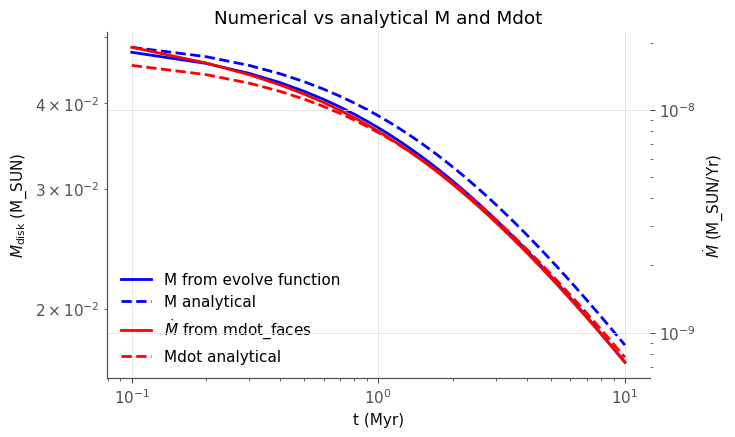

In [291]:
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax2 = ax1.twinx()

ax1.loglog(c.yr(t_d[1:])/1e6, mass_d[1:] / c.M_SUN, color='blue', label='M from evolve function')
ax1.loglog(c.yr(t_d[1:])/1e6, m_ana / c.M_SUN, color='blue', label='M analytical', linestyle = '--')
ax1.set_xlabel('t (Myr)')
ax1.set_ylabel(r'$M_{\rm disk}$ (M_SUN)')

ax2.loglog(c.yr(t_d[1:])/1e6, mdot_star[1:] * (c.MYR / 1e6) / c.M_SUN, color='red', label=r'$\dot M$ from mdot_faces')
ax2.loglog(c.yr(t_d[1:])/1e6, mdot_ana * (c.MYR / 1e6) / c.M_SUN, color='red', label='Mdot analytical', linestyle = '--')
ax2.set_ylabel(r'$\dot M$ (M_SUN/Yr)')


h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2)
ax1.set_title("Numerical vs analytical M and Mdot")
plt.savefig("prob4c_hw3.png")

In [292]:
one_My = np.argmin(np.abs(c.yr(t_d[1:])/1e6 - 1))
two_My = np.argmin(np.abs(c.yr(t_d[1:])/1e6 - 2))
three_My = np.argmin(np.abs(c.yr(t_d[1:])/1e6 - 3))

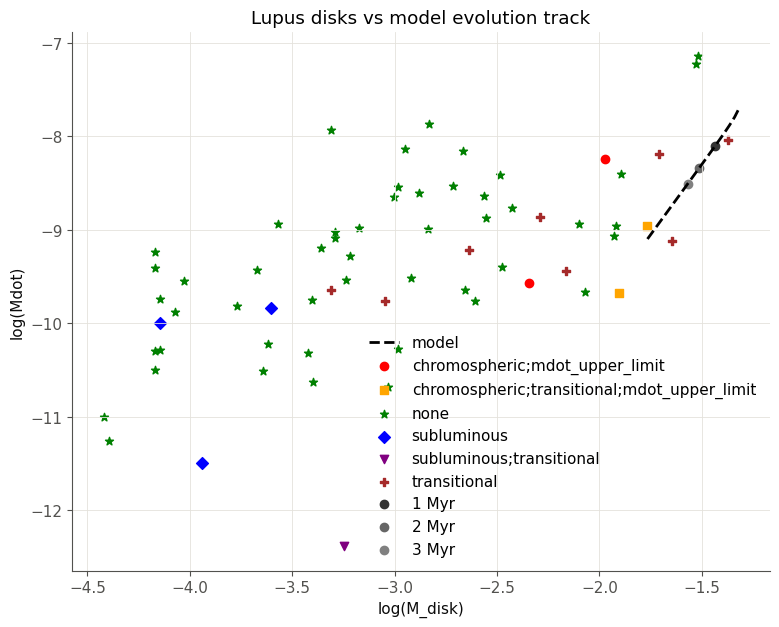

In [293]:
fig, ax = plt.subplots(figsize=(9, 7))
M_track = np.log10(mass_d[1:] / c.M_SUN)
logMdot_track = np.log10(mdot_star[1:] * (c.MYR / 1e6) / c.M_SUN)
ax.plot(M_track, logMdot_track, color = 'black', linestyle = '--', lw=2, label='model')
for (flag, group), m, color in zip(lupus_disks_full.groupby('flag'), markers, colors):
    ax.scatter(np.log10(group['M_disk']), group['log_mdot'], marker=m, label=flag, color=color)
ax.scatter(M_track[one_My], logMdot_track[one_My], color = '0.2', label = '1 Myr')
ax.scatter(M_track[two_My], logMdot_track[two_My], color = '0.4', label = '2 Myr')
ax.scatter(M_track[three_My], logMdot_track[three_My], color = '0.5', label = '3 Myr')
ax.set_xlabel("log(M_disk)")
ax.set_ylabel("log(Mdot)")
ax.legend()
ax.set_title("Lupus disks vs model evolution track")
plt.savefig("prob4c_plot2_hw3.png")

### Part (d)

#### The Lupus disks do not drain on the timescale the viscous model predicts. The slope is much steaper than the track of the Lupus disks.
#### From problem 2b, sepately performing the optically thin gas assumption increases the disk mass by about 2 orders of magnitude. It seems that, if you assume the gas is optically thin, you get a larger disk mass, given the same time, which would give you a less steep slope than what's plotted here. That would match the trend in the Lupus disks.
#### So, the assumption that the disk is isothermal at 20 K is what causes the slope from the model to over estimate the draining of the disks. 